In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numba import jit
from scipy import interpolate
from scipy.optimize import minimize

In [2]:
def P_from_nb(n_list, K, Gam):
    p = K*(n_list)**(Gam)
    return p

@jit(nopython=True)
def mu_from_nb(n_list, K, Gam, m0):
    t1 = ((K*Gam)/(Gam - 1))*((n_list)**(Gam - 1))
    re = t1 + m0
    return re

@jit(nopython=True)
def e_from_n(n_list, K, Gam, m0):
    t1 = (K * ((n_list) ** Gam)) / (Gam - 1)
    t2 = t1 + (m0 * (n_list))
    return t2

In [3]:
# Initial Values :
g_quark = 2.5
n_quark = np.linspace(0.5344,1,5000)
p = 63.177
e = 318.26 + 253.89

n_had =np.linspace(0.16,0.4,5000)
Gam_had = 4.921
m0_had = 939.56
K_had = 17906.60 

n_total = np.linspace(0.16,1,5000)

In [4]:
K_quark = p / (n_quark[0] ** g_quark)
m0_quark = (e - (K_quark * (n_quark[0] ** g_quark)) / (g_quark - 1)) / n_quark[0]

# Hadronic EOS
p_had = P_from_nb(n_total, K_had, Gam_had)
mu_had = mu_from_nb(n_total, K_had, Gam_had, m0_had)

# Quark EOS
p_quark = P_from_nb(n_total, K_quark, g_quark)
mu_quark = mu_from_nb(n_total, K_quark, g_quark, m0_quark)

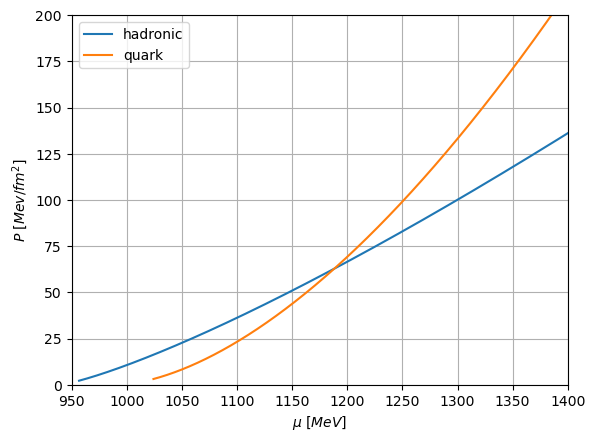

In [5]:
plt.plot(mu_had, p_had, label = "hadronic")
plt.plot(mu_quark, p_quark, label = "quark")

plt.xlim([950,1400])
plt.ylim([0,200])
plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.legend()
plt.grid()

In [6]:
mu_quark_0 = (mu_quark - 50)

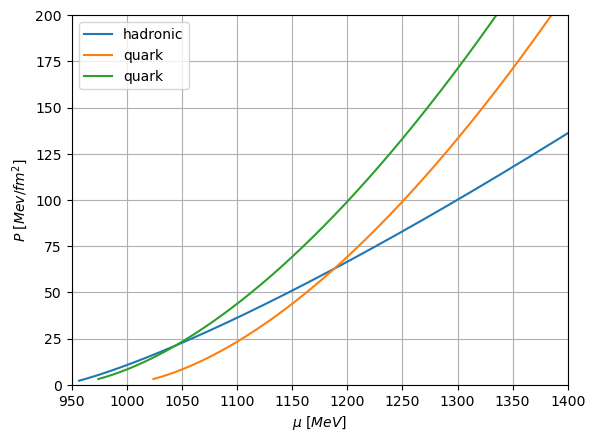

In [7]:
plt.plot(mu_had, p_had, label = "hadronic")
plt.plot(mu_quark, p_quark, label = "quark")
plt.plot(mu_quark_0, p_quark, label = "quark")

plt.xlim([950,1400])
plt.ylim([0,200])
plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.legend()
plt.grid()

The index is: 440 the mu value is: 1044.044044044044
Critical Chemical Potential is, mu_c: 1044.044044044044


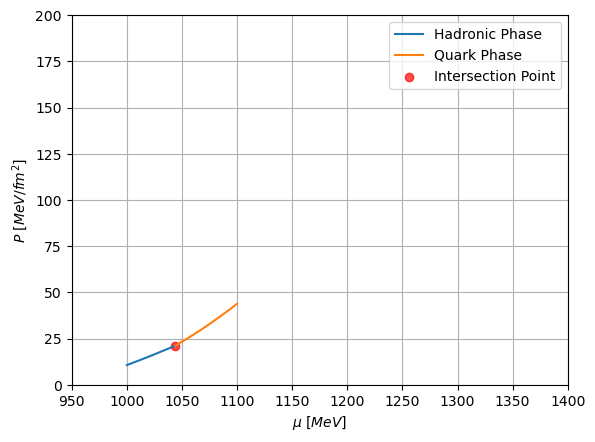

In [9]:
# Assuming mu1_b, P_1_all, mu_quark, and P_3_all are already defined
x1 = np.array(mu_had)
y1 = np.array(p_had)

x2 = np.array(mu_quark_0)
y2 = np.array(p_quark)

P_h_int_func = interpolate.interp1d(x1, y1)
P_q_int_func = interpolate.interp1d(x2, y2)

mu_new = np.linspace(1000, 1100, 1000)
P_had_array = P_h_int_func(mu_new)
P_quark_array = P_q_int_func(mu_new)

# Calculate the difference and find the intersection
y_diff = np.abs(P_had_array - P_quark_array)
index_intersect = np.argmin(y_diff)
x_intersect = mu_new[index_intersect]
y_intersect = P_had_array[index_intersect]

print("The index is:", index_intersect, "the mu value is:", x_intersect)
print("Critical Chemical Potential is, mu_c:", x_intersect)

# Split the arrays at the intersection point
mu_had = mu_new[:index_intersect + 1]
P_had = P_had_array[:index_intersect + 1]
mu_quark_2 = mu_new[index_intersect:]
P_quark_2 = P_quark_array[index_intersect:]

# Plotting the updated arrays
plt.plot(mu_had, P_had, label='Hadronic Phase')
plt.plot(mu_quark_2, P_quark_2, label='Quark Phase')
plt.scatter(x_intersect, y_intersect, color="red", alpha=0.7, label='Intersection Point')
plt.xlim([950,1400])
plt.ylim([0,200])
plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [MeV/fm^2]$")
plt.legend()
plt.grid()
plt.show()

In [10]:
nav =[1,2]
v =[10]
k=nav+v

In [11]:
k

[1, 2, 10]

In [12]:
# Calculate the difference between hadronic and quark phases
y_diff = np.abs(P_had_array - P_quark_array)
index_intersect = np.argmin(y_diff)  # Approximate intersection index in the interpolated array

# Get the approximate intersection point
x_intersect = mu_new[index_intersect]

# Find the closest index in the original arrays to this intersection point
index_had_closest = (np.abs(x1 - x_intersect)).argmin()
index_quark_closest = (np.abs(x2 - x_intersect)).argmin()

# Slice the original arrays at the closest intersection points
mu_had = x1[:index_had_closest]
np.append(mu_had,x_intersect)
P_had = y1[:index_had_closest]
np.append(P_had,y_intersect)
mu_quark_0 = x2[index_quark_closest:]
P_quark = y2[index_quark_closest:]


# Combine the original arrays at the intersection point
combined_mu = np.concatenate((mu_had, mu_quark_0[1:]))
combined_P = np.concatenate((P_had, P_quark[1:]))

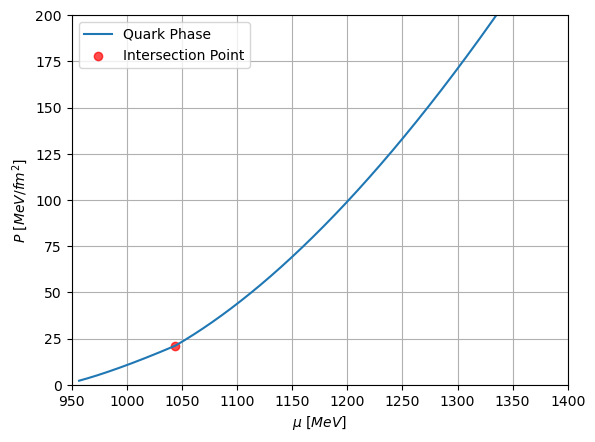

In [13]:
plt.plot(combined_mu, combined_P, label='Quark Phase')
plt.scatter(x_intersect, y_intersect, color="red", alpha=0.7, label='Intersection Point')
plt.xlim([950,1400])
plt.ylim([0,200])
plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [MeV/fm^2]$")
plt.legend()
plt.grid()
plt.show()

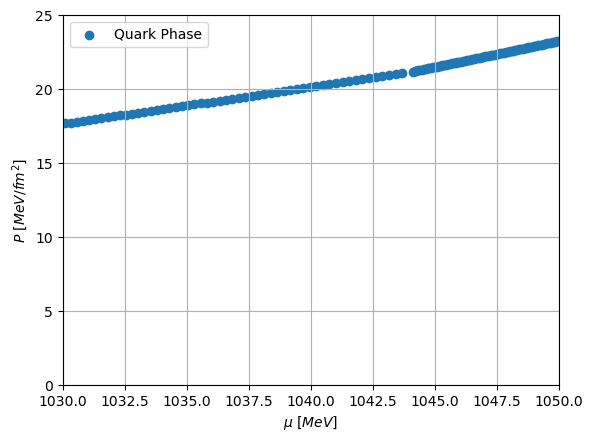

In [14]:
plt.scatter(combined_mu, combined_P, label='Quark Phase')
#plt.scatter(x_intersect, y_intersect, color="red", alpha=0.7, label='Intersection Point')
plt.xlim([1030,1050])
plt.ylim([0,25])
plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [MeV/fm^2]$")
plt.legend()
plt.grid()
plt.show()

In [15]:
gradient_0 = np.gradient(combined_P, combined_mu)
e_0 = (gradient_0*combined_mu)-combined_P

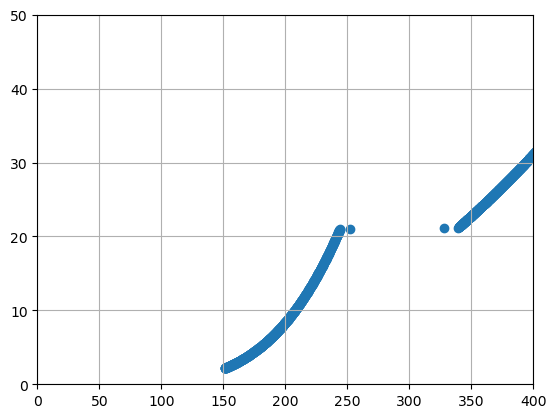

In [18]:
plt.scatter(e_0,combined_P)
plt.xlim([0,400])
plt.ylim([0,50])
plt.grid()
plt.show()

In [19]:
cs_0 = np.gradient(combined_P,e_0)

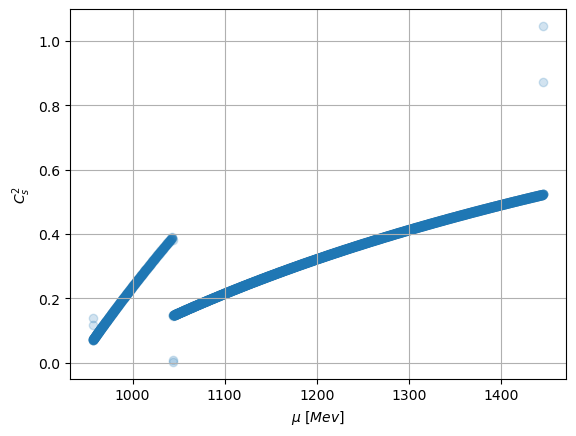

In [87]:
plt.scatter(combined_mu,cs_0,alpha=0.2);
plt.grid()
plt.xlabel(r"$\mu \ [Mev]$")
plt.ylabel(r"$C_s^2$")
plt.show();

In [8]:
print(combined_P[index_had_closest])
print(combined_P[index_had_closest+1])
print(combined_P[index_had_closest-1])

NameError: name 'combined_P' is not defined

In [9]:
mu_quark_new = []
for i in range(100):
    mu_quark_0 = (mu_quark - 50 + i)
    mu_quark_new.append(mu_quark_0)

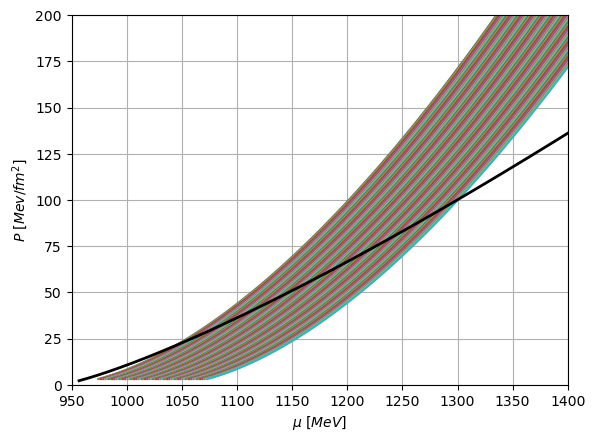

In [10]:
for i in range(len(mu_quark_new)):  # Assuming mu_quark_new is a list of lists
    plt.plot(mu_quark_new[i], p_quark, label=f"quark set {i+1}")

plt.plot(mu_had, p_had, label="hadronic", color='black', linewidth=2)  # Hadronic plot
plt.xlim([950, 1400])
plt.ylim([0, 200])
plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
#plt.legend(loc='upper right', bbox_to_anchor=(1.15, 1))  # Adjust legend position to handle many labels
plt.grid()
plt.show()


In [11]:
len(mu_quark_new)

100

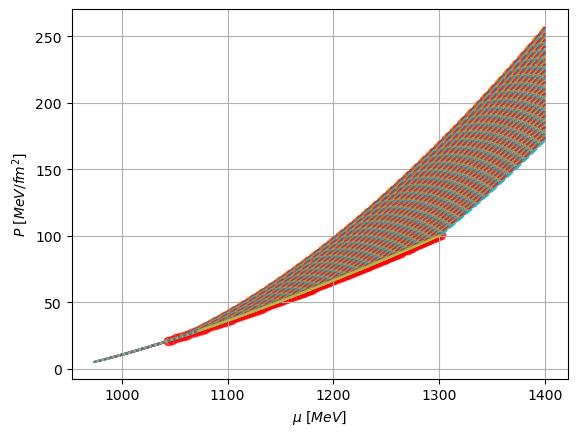

In [27]:
x1 = np.array(mu_had)
y1 = np.array(p_had)

# Interpolate the hadronic phase data
P_h_int_func = interpolate.interp1d(x1, y1)

# Generate a new mu array for interpolation

#P_had_array = P_h_int_func(mu_new)

#plt.plot(mu_new, P_had_array, label="Hadronic Phase", color='black', linewidth=2)

# Loop over all the mu_quark sets in mu_quark_new
for i, mu_quark_set in enumerate(mu_quark_new):

    # Generate a new mu array for interpolation
    mu_new = np.linspace(min(mu_quark_set), 1400, 1000)
    P_had_array = P_h_int_func(mu_new)

    x2 = np.array(mu_quark_set)
    y2 = np.array(p_quark)  # Assuming P_3_all is the same for all quark sets

    # Interpolate quark phase data
    P_q_int_func = interpolate.interp1d(x2, y2)

    # Interpolated quark phase pressures
    P_quark_array = P_q_int_func(mu_new)

    # Calculate the difference between hadronic and quark phases
    y_diff = np.abs(P_had_array - P_quark_array)
    index_intersect = np.argmin(y_diff)  # Find where the phases are closest
    x_intersect = mu_new[index_intersect]
    y_intersect = P_had_array[index_intersect]

    # Split the arrays at the intersection point
    mu_had_1 = mu_new[:index_intersect-1]
    P_had = P_had_array[:index_intersect-1]
    mu_quark_2 = mu_new[index_intersect+1:]
    P_quark_2 = P_quark_array[index_intersect+1:]

    # Plotting hadronic and quark phases for this mu_quark set
    plt.plot(mu_had_1, P_had, label=f'Hadronic Phase {i+1}', linestyle='-')
    plt.plot(mu_quark_2, P_quark_2, label=f'Quark Phase {i+1}', linestyle='--')

    # Plot the intersection point
    plt.scatter(x_intersect, y_intersect, color="red", alpha=0.7, label=f'Intersection {i+1}')

# Final plot settings
plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [MeV/fm^2]$")
#plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1))  # Adjust to fit many labels
plt.grid()
plt.show()


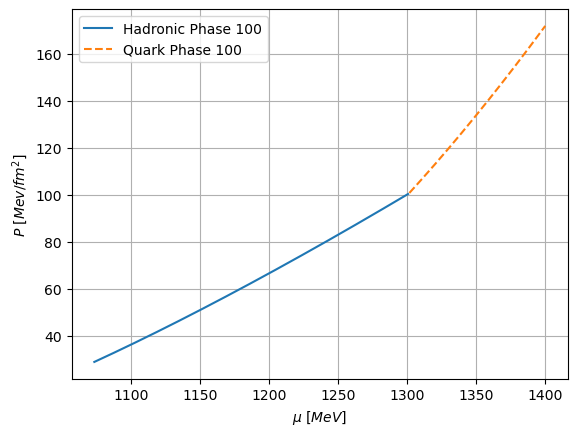

In [13]:
plt.plot(mu_had_1, P_had, label=f'Hadronic Phase {i+1}', linestyle='-')
plt.plot(mu_quark_2, P_quark_2, label=f'Quark Phase {i+1}', linestyle='--')

#plt.xlim([950,1400])
#plt.ylim([0,200])
plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.legend()
plt.grid()

In [14]:
mu = np.concatenate((mu_had_1[:],mu_quark_2[:]))
p = np.concatenate((P_had[:],P_quark_2[:]))

In [15]:
gradient_12 = np.gradient(p, mu)
e_curve_12 = (gradient_12*mu)-p

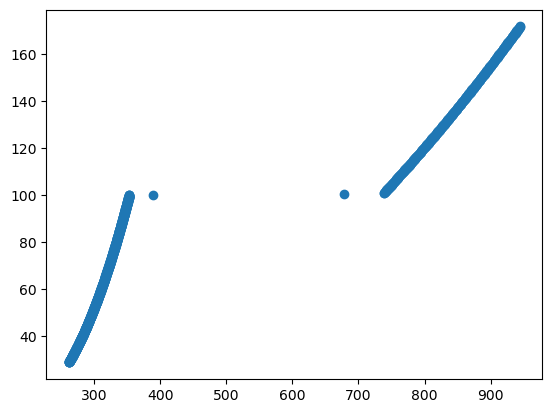

In [16]:
plt.scatter(e_curve_12,p)
plt.show()

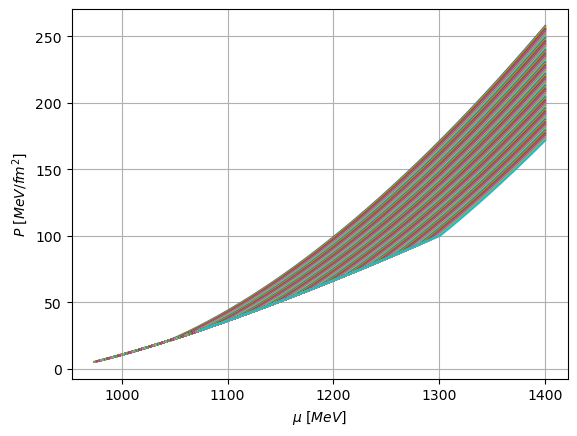

In [17]:
x1 = np.array(mu_had)
y1 = np.array(p_had)

# Interpolate the hadronic phase data
P_h_int_func = interpolate.interp1d(x1, y1)



# List to store combined curves for each quark phase
combined_mu_curves = []
combined_P_curves = []

# Loop over all the mu_quark sets in mu_quark_new
for i, mu_quark_set in enumerate(mu_quark_new):
    x2 = np.array(mu_quark_set)
    y2 = np.array(p_quark)  # Assuming P_3_all is the same for all quark sets

    # Generate a new mu array for interpolation
    mu_new = np.linspace(min(mu_quark_set), 1400, 1000)
    P_had_array = P_h_int_func(mu_new)

    # Interpolate quark phase data
    P_q_int_func = interpolate.interp1d(x2, y2)

    # Interpolated quark phase pressures
    P_quark_array = P_q_int_func(mu_new)

    # Calculate the difference between hadronic and quark phases
    y_diff = np.abs(P_had_array - P_quark_array)
    index_intersect = np.argmin(y_diff)  # Find where the phases are closest
    x_intersect = mu_new[index_intersect]
    y_intersect = P_had_array[index_intersect]

    # Split the arrays at the intersection point
    mu_had_1 = mu_new[:index_intersect+1]
    P_had = P_had_array[:index_intersect+1]
    mu_quark_2 = mu_new[index_intersect:]
    P_quark_2 = P_quark_array[index_intersect:]

    # Combine mu_had and mu_quark_2, P_had and P_quark_2
    combined_mu = np.concatenate((mu_had_1, mu_quark_2))
    combined_P = np.concatenate((P_had, P_quark_2))

    # Store the combined curves in the list
    combined_mu_curves.append(combined_mu)
    combined_P_curves.append(combined_P)

# Optionally, plot one of the combined curves as an example
for i in range(len(combined_mu_curves)):
    plt.plot(combined_mu_curves[i], combined_P_curves[i], label=f"Combined Curve {i+1}")

# Final plot settings
plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [MeV/fm^2]$")
#plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1))
plt.grid()
plt.show()

# Now the combined curves are stored in combined_mu_curves and combined_P_curves


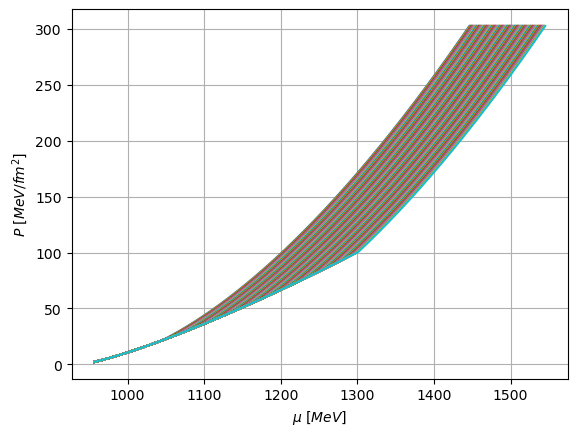

In [23]:
x1 = np.array(mu_had)
y1 = np.array(p_had)

# Interpolate the hadronic phase data
P_h_int_func = interpolate.interp1d(x1, y1)

# List to store combined curves for each quark phase
combined_mu_curves = []
combined_P_curves = []
P_crit = []
mu_crit = []

# Loop over all the mu_quark sets in mu_quark_new
for i, mu_quark_set in enumerate(mu_quark_new):
    x2 = np.array(mu_quark_set)
    y2 = np.array(p_quark)  # Assuming P_3_all is the same for all quark sets

    # Generate a new mu array for interpolation
    mu_new = np.linspace(min(mu_quark_set), 1400, 1000)
    P_had_array = P_h_int_func(mu_new)

    # Interpolate quark phase data
    P_q_int_func = interpolate.interp1d(x2, y2)
    P_quark_array = P_q_int_func(mu_new)

    # Calculate the difference between hadronic and quark phases
    y_diff = np.abs(P_had_array - P_quark_array)
    index_intersect = np.argmin(y_diff)  # Approximate intersection index in the interpolated array

    # Get the approximate intersection point
    x_intersect = mu_new[index_intersect]

    # Find the closest index in the original arrays to this intersection point
    index_had_closest = (np.abs(x1 - x_intersect)).argmin()
    index_quark_closest = (np.abs(x2 - x_intersect)).argmin()

    # Slice the original arrays at the closest intersection points
    mu_had_1 = x1[:index_had_closest-1]
    P_had = y1[:index_had_closest-1]
    mu_quark_2 = x2[1+index_quark_closest:]
    P_quark_2 = y2[1+index_quark_closest:]

    P_crit.append(P_quark_2[0])
    mu_crit.append(mu_quark_2[0])

    # Combine the original arrays at the intersection point
    combined_mu = np.concatenate((mu_had_1, mu_quark_2))
    combined_P = np.concatenate((P_had, P_quark_2))

    # Store the combined curves in the list
    combined_mu_curves.append(combined_mu)
    combined_P_curves.append(combined_P)

# Plot the combined curves
for i in range(len(combined_mu_curves)):
    plt.plot(combined_mu_curves[i], combined_P_curves[i], label=f"Combined Curve {i+1}")

# Final plot settings
plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [MeV/fm^2]$")
# plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1))  # Uncomment if legend is needed
plt.grid()
plt.show()


In [24]:
combined_n = []
combined_e = []
combined_cs2 = []
# Loop over each combined curve to calculate the gradient
for i in range(len(combined_P_curves)):
    P_curve = combined_P_curves[i]
    mu_curve = combined_mu_curves[i]

    # Compute the gradient of P with respect to mu
    gradient = np.gradient(P_curve, mu_curve)
    
    # Append the gradient to the list
    combined_n.append(gradient)

    e_curve = (gradient*mu_curve)-P_curve
    combined_e.append(e_curve)
    cs2 = np.gradient(P_curve,e_curve)
    combined_cs2.append(cs2)

In [28]:
e_total, p_total, mu_total, cs_total = combined_e, combined_P_curves, combined_mu_curves, combined_cs2

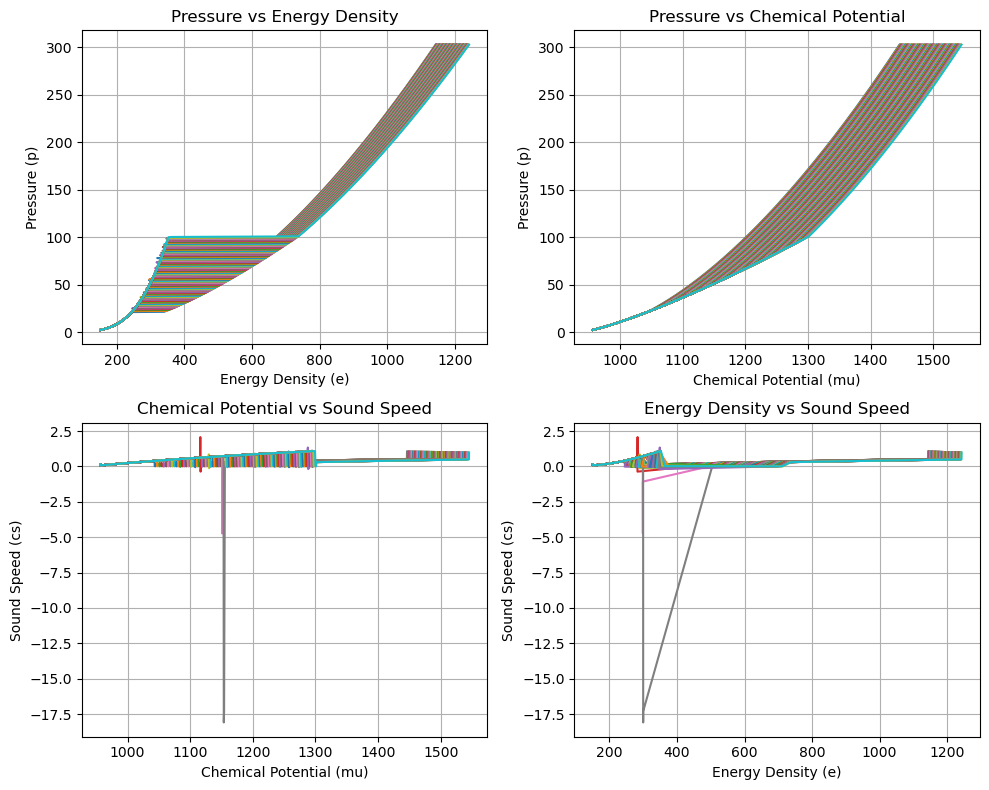

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for i in range(len(p_total)):
    # Plot 1: Pressure vs Energy Density
    axes[0, 0].plot(e_total[i], p_total[i])

    # Plot 2: Pressure vs Chemical Potential
    axes[0, 1].plot(mu_total[i], p_total[i])

    # Plot 3: Chemical Potential vs Sound Speed
    axes[1, 0].plot(mu_total[i], cs_total[i])

    # Plot 4: Energy Density vs Sound Speed
    axes[1, 1].plot(e_total[i], cs_total[i])

# Adding titles, labels, and legends after the loop

# Plot 1: Pressure vs Energy Density
axes[0, 0].set_title('Pressure vs Energy Density')
axes[0, 0].set_xlabel('Energy Density (e)')
axes[0, 0].set_ylabel('Pressure (p)')
axes[0, 0].grid(True)
#axes[0, 0].legend()

# Plot 2: Pressure vs Chemical Potential
axes[0, 1].set_title('Pressure vs Chemical Potential')
axes[0, 1].set_xlabel('Chemical Potential (mu)')
axes[0, 1].set_ylabel('Pressure (p)')
axes[0, 1].grid(True)
#axes[0, 1].legend()

# Plot 3: Chemical Potential vs Sound Speed
axes[1, 0].set_title('Chemical Potential vs Sound Speed')
axes[1, 0].set_ylabel('Sound Speed (cs)')
axes[1, 0].set_xlabel('Chemical Potential (mu)')
axes[1, 0].grid(True)
#axes[1, 0].legend()

# Plot 4: Energy Density vs Sound Speed
axes[1, 1].set_title('Energy Density vs Sound Speed')
axes[1, 1].set_ylabel('Sound Speed (cs)')
axes[1, 1].set_xlabel('Energy Density (e)')
axes[1, 1].grid(True)
#axes[1, 1].legend()

# Adjust spacing between subplots
plt.tight_layout()

# Show the plot
plt.show()

In [22]:
P_all = []
P_all_1 = []
P_max_points = []
P_max_points_1 = []

# Iterate through each mu_total and p_total index
for index in range(len(mu_total)):

    P_crit_1 = P_crit[index]*(1+0.01)
    P_crit_2 = P_crit[index]*(1+0.3)
    P_crit_new = np.linspace(P_crit_1,P_crit_2,1000)

    b_optimal = []
    a_optimal = []
    P_optimal = []
    min_distance_points = []
    min_distances = []

    for P in P_crit_new:
        # Define your points
        x1, y1 = mu_total[index][0], p_total[index][0]  # First point the curve must pass through
        x2, y2 = mu_crit[index],P   # Critical point

        # For inequality constraint defining hadronic part.
        x_values = np.array(mu_total[index][1:])  # Hadronic part x_values
        f_values = np.array(p_total[index][1:])   # Corresponding y_values

        # Define the quadratic function
        def quadratic(x, a, b):
            return a * (x - x2)**2 + b * (x - x2) + y2

        # Objective function: sum of squared differences (least distance point)
        def objective(params):
            a, b = params
            return 0

        # Initial guess for parameters
        initial_guess = [0, 0]

        # Constraint: quadratic must pass through the first point (x1, y1)
        def eq_constraint(params):
            a, b = params
            return quadratic(x1, a, b) - y1

        # Inequality constraint: ensure quadratic stays above hadronic part
        def ineq_constraint(params):
            a, b = params
            return quadratic(x_values, a, b) - f_values

        # Define the constraints
        constraints = [
            {'type': 'eq', 'fun': eq_constraint},  # Must pass through (x1, y1)
            {'type': 'ineq', 'fun': ineq_constraint},  # Must stay above hadronic data
        ]

        # Perform the optimization
        result = minimize(objective, initial_guess, constraints=constraints)

        if result.success:
            a_opt, b_opt = result.x

            # Find the least distance point
            min_distance = float('inf')
            closest_point = None

            # Calculate the quadratic value and find minimum distance
            for x, f in zip(x_values, f_values):
                y_quad = quadratic(x, a_opt, b_opt)
                distance = np.abs(y_quad - f)  # Only y-direction distance
                if distance < min_distance:
                    min_distance = distance
                    closest_point = (x, y_quad)

            # Save the optimal solution
            a_optimal.append(a_opt)
            b_optimal.append(b_opt)
            P_optimal.append(P)
            min_distance_points.append(closest_point)
            min_distances.append(min_distance)

        else:
            continue
    # Convert min_distances to a NumPy array
    min_distances = np.array(min_distances)
    P_optimal = np.array(P_optimal)
    min_distance_points = np.array(min_distance_points)


    # Check if min_distances and P_optimal contain values
    if min_distances.size > 0 and P_optimal.size > 0 and min_distance_points.size > 0:
        # Find the index of the minimum distance across all runs
        index = min_distances.argmin()

        # Save a specific optimal value to P_all based on index
        P_all.append(P_optimal[index])
        P_all_1.append(P_optimal[0])
        P_max_points.append(min_distance_points[index])
        P_max_points_1.append(min_distance_points[0])
    else:
        # Append zeros if arrays are empty
        P_all.append(0)
        P_all_1.append(0)
        P_max_points.append(0)
        P_max_points_1.append(0)



KeyboardInterrupt: 

In [ ]:
P_all = []
P_all_1 = []
P_max_points = []
P_max_points_1 = []

# Iterate through each mu_total and p_total index
for i in range(len(mu_total)):

    P_crit_1 = P_crit[i] * (1 + 0.01)
    P_crit_2 = P_crit[i] * (1 + 0.3)
    P_crit_new = np.linspace(P_crit_1, P_crit_2, 1000)

    b_optimal = []
    a_optimal = []
    P_optimal = []
    min_distance_points = []
    min_distances = []

    for P in P_crit_new:
        # Define your points
        x1, y1 = mu_total[i][0], p_total[i][0]  # First point the curve must pass through
        x2, y2 = mu_crit[i], P_crit[i]   # Critical point

        # For inequality constraint defining hadronic part.
        x_values = np.array(mu_total[i][1:])  # Hadronic part x_values
        f_values = np.array(p_total[i][1:])   # Corresponding y_values

        # Define the quadratic function
        def quadratic(x, a, b):
            return a * (x - x2)**2 + b * (x - x2) + y2

        # Objective function: sum of squared differences (least distance point)
        def objective(params):
            a, b = params
            return np.sum((quadratic(x_values, a, b) - f_values)**2)  # Example objective calculation

        # Initial guess for parameters
        initial_guess = [0, 0]

        # Constraint: quadratic must pass through the first point (x1, y1)
        def eq_constraint(params):
            a, b = params
            return quadratic(x1, a, b) - y1

        # Inequality constraint: ensure quadratic stays above hadronic part
        def ineq_constraint(params):
            a, b = params
            return quadratic(x_values, a, b) - f_values

        # Define the constraints
        constraints = [
            {'type': 'eq', 'fun': eq_constraint},  # Must pass through (x1, y1)
            {'type': 'ineq', 'fun': ineq_constraint},  # Must stay above hadronic data
        ]

        # Perform the optimization
        result = minimize(objective, initial_guess, constraints=constraints)

        if result.success:
            a_opt, b_opt = result.x

            # Find the least distance point
            min_distance = float('inf')
            closest_point = None

            # Calculate the quadratic value and find minimum distance
            for x, f in zip(x_values, f_values):
                y_quad = quadratic(x, a_opt, b_opt)
                distance = np.abs(y_quad - f)  # Only y-direction distance
                if distance < min_distance:
                    min_distance = distance
                    closest_point = (x, y_quad)

            # Save the optimal solution
            a_optimal.append(a_opt)
            b_optimal.append(b_opt)
            P_optimal.append(P)
            min_distance_points.append(closest_point)
            min_distances.append(min_distance)

    # Convert min_distances to a NumPy array
    min_distances = np.array(min_distances)

    # Check if min_distances and P_optimal contain values
    if min_distances.size > 0 and len(P_optimal) > 0 and len(min_distance_points) > 0:
        # Find the index of the minimum distance across all runs
        min_index = min_distances.argmin()

        # Save a specific optimal value to P_all based on index
        P_all.append(P_optimal[min_index])
        P_all_1.append(P_optimal[0])
        P_max_points.append(min_distance_points[min_index])
        P_max_points_1.append(min_distance_points[0])
    else:
        # Append zeros if arrays are empty
        P_all.append(0)
        P_all_1.append(0)
        P_max_points.append((0, 0))  # Tuple with zero values for x and y
        P_max_points_1.append((0, 0))


In [27]:
len(P_all_1)

100

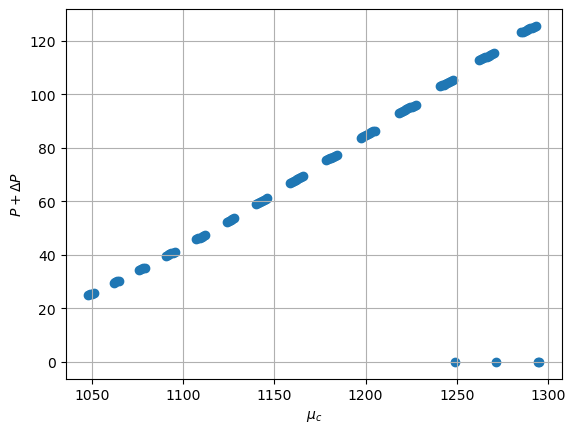

In [16]:
plt.scatter(mu_crit,P_all_1);
plt.grid();
plt.xlabel(r'$\mu_c$');
plt.ylabel(r'$P + \Delta P $');
plt.show();

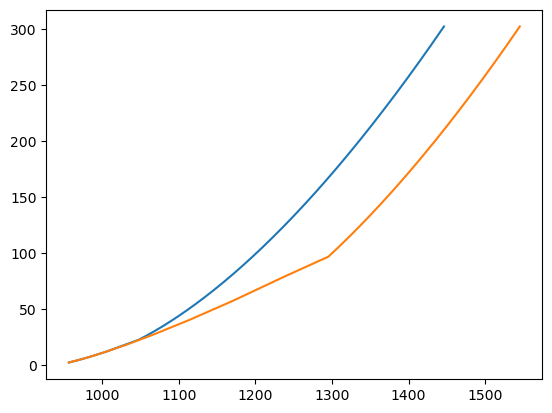

In [19]:
plt.plot(mu_total[0],p_total[0])
plt.plot(mu_total[-1],p_total[-1])
plt.show()

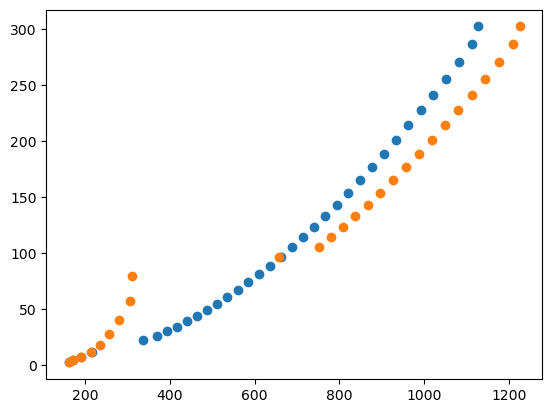

In [21]:
plt.scatter(e_total[0],p_total[0])
plt.scatter(e_total[-1],p_total[-1])
plt.show()

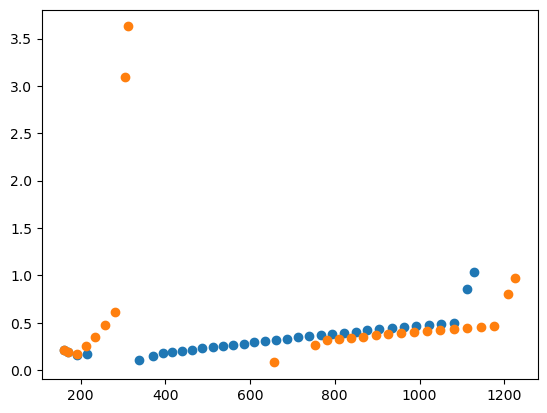

In [23]:
plt.scatter(e_total[0],cs_total[0])
plt.scatter(e_total[-1],cs_total[-1])
plt.show()

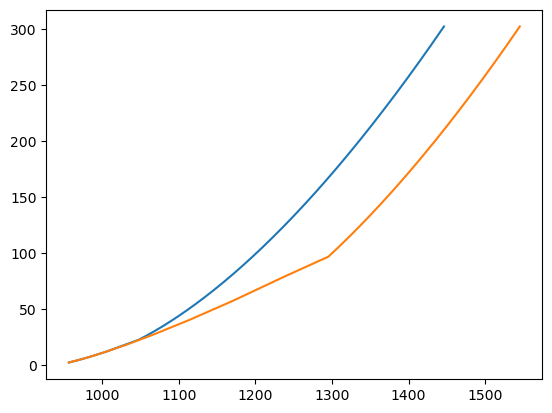

In [24]:
plt.plot(combined_mu_curves[0],combined_P_curves[0])
plt.plot(combined_mu_curves[-1],combined_P_curves[-1])
plt.show()

In [ ]:
plt.plot(combined_mu_curves[0],combined_P_curves[0])
plt.plot(combined_mu_curves[-1],combined_P_curves[-1])
plt.show()

In [28]:

# Compute the gradient of P with respect to mu
gradient_11 = np.gradient(combined_P_curves[0], combined_mu_curves[0])

e_curve_11 = (gradient_11*combined_mu_curves[0])-combined_P_curves[0]

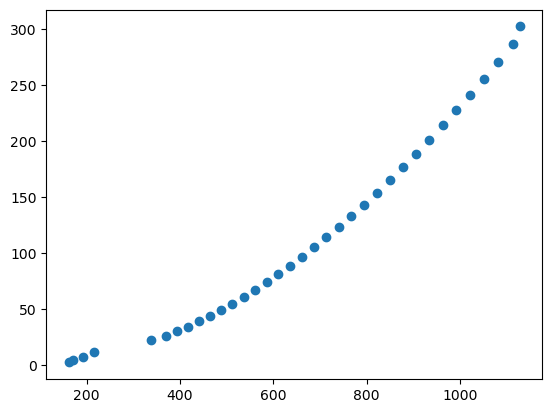

In [29]:
plt.scatter(e_curve_11,combined_P_curves[0])

#plt.plot(c,combined_P_curves[-1])
plt.show()

In [30]:
# Compute the gradient of P with respect to mu
gradient_12 = np.gradient(combined_P_curves[-1], combined_mu_curves[-1])
e_curve_12 = (gradient_12*combined_mu_curves[-1])-combined_P_curves[-1]

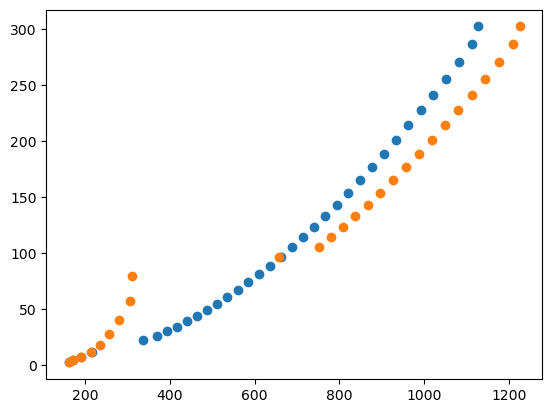

In [32]:
plt.scatter(e_curve_11,combined_P_curves[0])
plt.scatter(e_curve_12,combined_P_curves[-1])
plt.show()

/opt/anaconda3/envs/myenv1/lib/python3.12/site-packages/numpy/lib/function_base.py:1242: RuntimeWarning: divide by zero encountered in divide
  a = -(dx2)/(dx1 * (dx1 + dx2))
/opt/anaconda3/envs/myenv1/lib/python3.12/site-packages/numpy/lib/function_base.py:1243: RuntimeWarning: divide by zero encountered in divide
  b = (dx2 - dx1) / (dx1 * dx2)
/opt/anaconda3/envs/myenv1/lib/python3.12/site-packages/numpy/lib/function_base.py:1244: RuntimeWarning: divide by zero encountered in divide
  c = dx1 / (dx2 * (dx1 + dx2))
/opt/anaconda3/envs/myenv1/lib/python3.12/site-packages/numpy/lib/function_base.py:1250: RuntimeWarning: invalid value encountered in add
  out[tuple(slice1)] = a * f[tuple(slice2)] + b * f[tuple(slice3)] + c * f[tuple(slice4)]


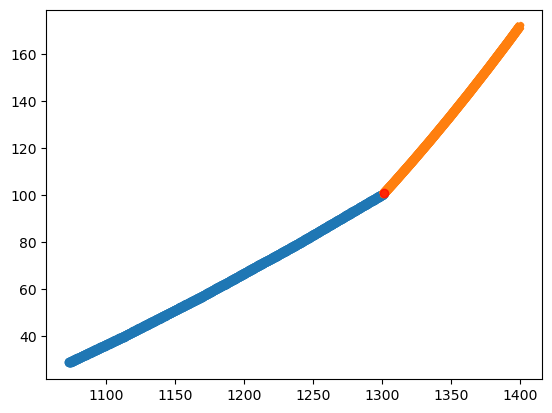

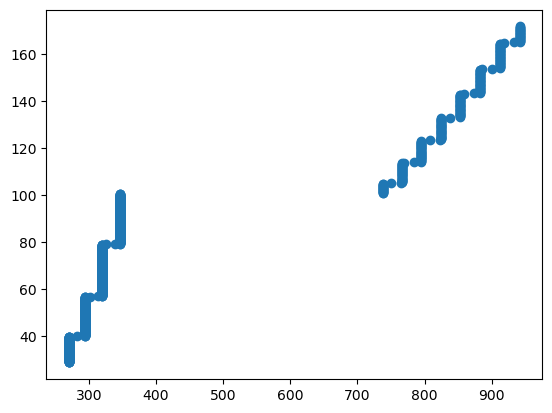

In [45]:
i=0


# Generate a new mu array for interpolation
mu_new = np.linspace(min(mu_quark_set), 1400, 1000)
P_had_array = P_h_int_func(mu_new)

x2 = np.array(mu_quark_set)
y2 = np.array(p_quark)  # Assuming P_3_all is the same for all quark sets


# Interpolate quark phase data
P_q_int_func = interpolate.interp1d(x2, y2)

# Interpolated quark phase pressures
P_quark_array = P_q_int_func(mu_new)

# Calculate the difference between hadronic and quark phases
y_diff = np.abs(P_had_array - P_quark_array)
index_intersect = np.argmin(y_diff)  # Find where the phases are closest
x_intersect = mu_new[index_intersect]
y_intersect = P_had_array[index_intersect]

# Split the arrays at the intersection point
mu_had_1 = mu_new[:index_intersect + 1]
P_had = P_had_array[:index_intersect + 1]
mu_quark_2 = mu_new[index_intersect:]
P_quark_2 = P_quark_array[index_intersect:]

mu_t = np.concatenate((mu_had_1,mu_quark_2))
p_t = np.concatenate((P_had,P_quark_2))
gradient_12 = np.gradient(p_t, mu_t)
e_curve_12 = (gradient_12*mu_t)-p_t
# Plotting hadronic and quark phases for this mu_quark set
plt.scatter(mu_had_1, P_had, label=f'Hadronic Phase {i+1}', linestyle='-')
plt.scatter(mu_quark_2, P_quark_2, label=f'Quark Phase {i+1}', linestyle='--')

# Plot the intersection point
plt.scatter(x_intersect, y_intersect, color="red", alpha=0.7, label=f'Intersection {i+1}')
plt.show()
plt.scatter(e_curve_12, p_t, label=f'Hadronic Phase {i+1}', linestyle='-')